In [1]:
import pandas as pd
import numpy as np
import os

# Folder path
folder = "acs_2024_1yr_csv"

files = [
    "csv_pus__psam_pusa.csv",
    "csv_pus__psam_pusb.csv",
    "csv_ppr__psam_p72.csv"
]

# Columns we need
cols = ["PINCP", "AGEP", "SCHL", "SEX", "WKHP", "STATE"]

df_list = []

for f in files:
    path = os.path.join(folder, f)
    temp = pd.read_csv(path, usecols=cols)
    df_list.append(temp)

df = pd.concat(df_list, ignore_index=True)

print("Combined shape:", df.shape)
df.head()

Combined shape: (3448793, 6)


,STATE,AGEP,SCHL,SEX,WKHP,PINCP
0,1,59,10.0,1,30.0,18500.0
1,1,43,17.0,1,NaN,0.0
2,1,75,16.0,2,NaN,27100.0
3,1,22,19.0,2,NaN,1000.0
4,1,51,16.0,1,NaN,0.0


In [2]:
# Convert SCHL to numeric (important)
df["SCHL"] = pd.to_numeric(df["SCHL"], errors="coerce")

# Create education groups
def make_edu_group(schl):
    if pd.isna(schl):
        return np.nan
    elif 1 <= schl <= 15:
        return "Less than high school"
    elif schl in [16, 17]:
        return "High school or equivalent"
    elif 18 <= schl <= 20:
        return "Some college or associate degree"
    elif schl == 21:
        return "Bachelor's degree"
    elif 22 <= schl <= 24:
        return "Graduate degree"
    else:
        return np.nan

df["edu_group"] = df["SCHL"].apply(make_edu_group)

# Check distribution
print(df["edu_group"].value_counts(dropna=False))

edu_group
Less than high school               812845
Some college or associate degree    805209
High school or equivalent           770752
Bachelor's degree                   585502
Graduate degree                     384827
NaN                                  89658
Name: count, dtype: int64


In [3]:
# Step 3: Create ML dataset (FULL POPULATION — no filtering)

ml_df = df[["PINCP", "AGEP", "edu_group", "SEX", "WKHP", "STATE"]].copy()

# Convert numeric columns
for col in ["PINCP", "AGEP", "WKHP", "STATE"]:
    ml_df[col] = pd.to_numeric(ml_df[col], errors="coerce")

# Drop missing values ONLY (no filtering)
ml_df = ml_df.dropna(subset=[
    "PINCP", "AGEP", "edu_group", "SEX", "WKHP", "STATE"
])  

# Optional: create working indicator (VERY useful)
ml_df["is_working"] = (ml_df["WKHP"] > 0).astype(int)

# Check dataset
print("Final dataset shape:", ml_df.shape)
print()
print(ml_df.head())

Final dataset shape: (1776716, 7)

      PINCP  AGEP                         edu_group  SEX  WKHP  STATE  \
0   18500.0    59             Less than high school    1  30.0      1   
7   30000.0    28  Some college or associate degree    1  72.0      1   
8    5100.0    18         High school or equivalent    2  20.0      1   
14   6000.0    19         High school or equivalent    2  40.0      1   
15  30600.0    44             Less than high school    1  35.0      1   

    is_working  
0            1  
7            1  
8            1  
14           1  
15           1  


In [4]:
# Step 4: Encode categorical variables

ml_encoded = pd.get_dummies(
    ml_df,
    columns=["edu_group", "SEX", "STATE"],
    drop_first=True
)

print("Encoded dataset shape:", ml_encoded.shape)
ml_encoded.head()

Encoded dataset shape: (1776716, 60)


,PINCP,AGEP,WKHP,is_working,edu_group_Graduate degree,edu_group_High school or equivalent,edu_group_Less than high school,edu_group_Some college or associate degree,SEX_2,STATE_2,...,STATE_47,STATE_48,STATE_49,STATE_50,STATE_51,STATE_53,STATE_54,STATE_55,STATE_56,STATE_72
0,18500.0,59,30.0,1,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
7,30000.0,28,72.0,1,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
8,5100.0,18,20.0,1,False,True,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
14,6000.0,19,40.0,1,False,True,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
15,30600.0,44,35.0,1,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [5]:
# Separate features and target

X = ml_encoded.drop(columns=["PINCP"])
y = ml_encoded["PINCP"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print(X.head())

X shape: (1776716, 59)
y shape: (1776716,)
    AGEP  WKHP  is_working  edu_group_Graduate degree  \
0     59  30.0           1                      False   
7     28  72.0           1                      False   
8     18  20.0           1                      False   
14    19  40.0           1                      False   
15    44  35.0           1                      False   

    edu_group_High school or equivalent  edu_group_Less than high school  \
0                                 False                             True   
7                                 False                            False   
8                                  True                            False   
14                                 True                            False   
15                                False                             True   

    edu_group_Some college or associate degree  SEX_2  STATE_2  STATE_4  ...  \
0                                        False  False    False    False  ... 

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

In [7]:
# Train Linear Regression
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

In [8]:
# Train Random Forest
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=50,
    max_depth=8,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

In [9]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

def evaluate(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return rmse, mae, r2

results = []

for name, pred in [
    ("Linear", y_pred_lr),
    ("Random Forest", y_pred_rf)
]:
    rmse, mae, r2 = evaluate(y_test, pred)
    results.append([name, rmse, mae, r2])

results_df = pd.DataFrame(results, columns=["Model", "RMSE", "MAE", "R2"])
results_df

,Model,RMSE,MAE,R2
0,Linear,78449.061207,42090.664737,0.244595
1,Random Forest,76591.847657,39125.067320,0.279938


The Random Forest model outperforms linear regression across all evaluation metrics. In particular, mean absolute error decreases from 42,091 to 39,125, representing an improvement of approximately 7%. Similarly, the R^2 increases from 0.245 to 0.280, indicating that the machine learning model captures additional variation in income. These results suggest that the relationship between income and demographic characteristics is nonlinear and involves interaction effects that are not fully captured by traditional linear models. The large magnitude of RMSE reflects the high variance and skewness of income, particularly among high-income individuals.

In [10]:
# feature importance
import pandas as pd
import matplotlib.pyplot as plt

# Get importance scores
importances = rf.feature_importances_

# Match with feature names
features = X.columns

feat_imp = pd.Series(importances, index=features).sort_values(ascending=False)

# Show top 15
print(feat_imp.head(15))

WKHP                                          0.315409
edu_group_Graduate degree                     0.300974
AGEP                                          0.146992
SEX_2                                         0.092278
edu_group_Some college or associate degree    0.051573
edu_group_Less than high school               0.042495
edu_group_High school or equivalent           0.036104
STATE_6                                       0.009495
STATE_36                                      0.001799
STATE_53                                      0.000768
STATE_34                                      0.000528
STATE_25                                      0.000421
STATE_11                                      0.000384
STATE_9                                       0.000312
STATE_12                                      0.000159
dtype: float64


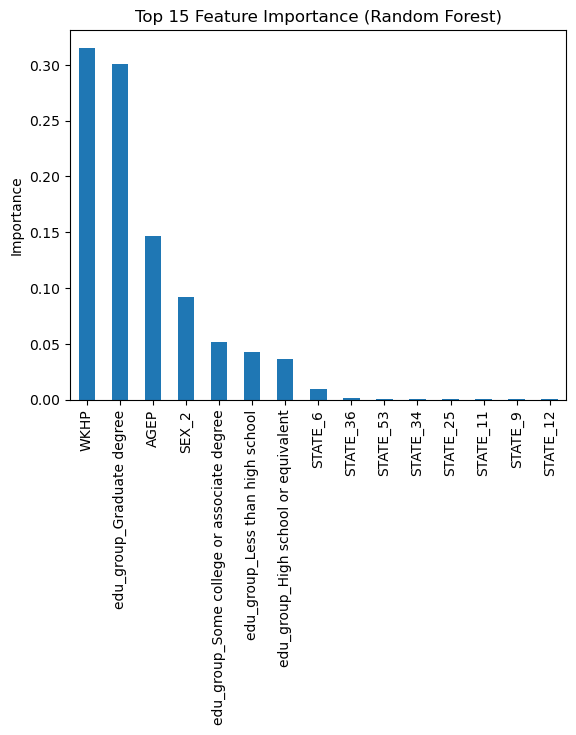

In [11]:
feat_imp.head(15).plot(kind="bar")
plt.title("Top 15 Feature Importance (Random Forest)")
plt.ylabel("Importance")
plt.show()

Labor supply(working hours) is the strongest predictor of income. Higher education (especially graduate degrees) has a large impact on income. Income varies significantly across the life cycle. There is a meaningful income difference across gender. Education matters at all levels, not just graduate degrees. state adds relatively little additional predictive power Once we control other variables, state becomes less important.

In [12]:
from xgboost import XGBRegressor
import time

xgb = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)

In [13]:
rmse, mae, r2 = evaluate(y_test, y_pred_xgb)
results_df.loc[len(results_df)] = ["XGBoost", rmse, mae, r2]

results_df

,Model,RMSE,MAE,R2
0,Linear,78449.061207,42090.664737,0.244595
1,Random Forest,76591.847657,39125.067320,0.279938
2,XGBoost,75765.922487,38450.755758,0.295384


Boosting methods provide the highest predictive accuracy for income. XGBoost reduces prediction error by nearly 9% compared to linear regression. Random Forest = averages many trees XGBoost = learns from mistakes iteratively

In [14]:
import pandas as pd
import numpy as np
import time

from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Make X numeric but memory-efficient
X_cv = X.copy()

bool_cols = X_cv.select_dtypes(include=["bool"]).columns
X_cv[bool_cols] = X_cv[bool_cols].astype(np.int8)

X_cv = X_cv.astype(np.float32)
y_cv = y.astype(np.float32)

cv = KFold(n_splits=3, shuffle=True, random_state=42)

models = {
    "Linear": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=50,
        max_depth=8,
        min_samples_leaf=20,
        random_state=42,
        n_jobs=1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=1
    )
}

scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2"
}

cv_results = []

for name, model in models.items():
    print(f"Running CV for {name}...")
    start = time.time()

    scores = cross_validate(
        model,
        X_cv,
        y_cv,
        cv=cv,
        scoring=scoring,
        n_jobs=1,          # IMPORTANT: prevents memory explosion
        return_train_score=False,
        error_score="raise"
    )

    end = time.time()
    print(f"{name} finished in {(end - start)/60:.2f} minutes")

    cv_results.append({
        "Model": name,
        "CV RMSE Mean": -scores["test_rmse"].mean(),
        "CV RMSE SD": scores["test_rmse"].std(),
        "CV MAE Mean": -scores["test_mae"].mean(),
        "CV MAE SD": scores["test_mae"].std(),
        "CV R2 Mean": scores["test_r2"].mean(),
        "CV R2 SD": scores["test_r2"].std(),
        "Time Minutes": (end - start) / 60
    })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df

Running CV for Linear...
Linear finished in 0.18 minutes
Running CV for Random Forest...
Random Forest finished in 16.42 minutes
Running CV for XGBoost...
XGBoost finished in 3.39 minutes


,Model,CV RMSE Mean,CV RMSE SD,CV MAE Mean,CV MAE SD,CV R2 Mean,CV R2 SD,Time Minutes
0,Linear,84879.096354,266.521961,46257.820312,39.989087,0.123816,0.000442,0.175607
1,Random Forest,76946.558664,207.200624,39130.434527,41.426112,0.279932,0.001076,16.421640
2,XGBoost,76099.145833,209.812205,38457.361979,34.705318,0.295705,0.001011,3.389076
